# 第五組：模型型特徵——GARCH(1,1) 條件波動

03 的特徵是對過去 K 線的算術；這裡的特徵是**模型的輸出**，模型參數本身是從資料估出來的，所以估計用了哪段歷史
也變成特徵「知道」的東西。對波動預測來說，最經典的模型型特徵就是 GARCH(1,1)：每天的變異數＝長期水準、
前一天的意外平方、前一天的變異數三者加權。它天生會「均值回歸」——高波動之後預測會往長期水準拉回，
這正是 HV20 做不到的事。

未來資訊有兩條管道會滲進來，本 notebook 兩條都堵住並實際測試：
1. **參數**：用全樣本估一次參數，2018 年的預測就帶著 2022 年的記憶。改用**重估時程**：暖身 250 天，
   之後每 63 天（一季）只用「到目前為止」的資料重估一次；進入封存期後不再重估，沿用最後一組參數。
2. **遞迴**：變異數遞迴的起始值（backcast）只能用訓練資料算，套用時不能讀到區塊內之後的報酬。

參考：ML4T 第 9 章、課程範本 `etfs/04_model_based_features`（C.3 GARCH 一節）。範本另外做了大盤的
隱馬可夫（HMM）狀態與分數差分；HMM 的值對每檔股票都一樣，無法做橫斷面排名，只可能幫助「整體配置」判斷，
列為下一步，本 notebook 不做。

In [1]:
from nb_utils import *                                       # 共用工具
style()                                                      # 圖表樣式
G = CFG["model_based"]["garch"]                              # GARCH 設定（寫在 setup.yaml）
BURN, EVERY = G["burnin_sessions"], G["refit_every"]         # 暖身天數、重估間隔
panel = pd.read_parquet(PROC / "panel.parquet")              # 清理後日資料
panel = panel[panel.sid.isin(STK) & panel.valid].sort_values(["sid", "date"])  # 股票、有效交易日
print(f"GARCH(1,1)：每檔暖身 {BURN} 個交易日、每 {EVERY} 日重估一次；{HOLDOUT_START.date()} 之後凍結參數")  # 印出

GARCH(1,1)：每檔暖身 250 個交易日、每 63 日重估一次；2025-01-01 之後凍結參數


## A. 走勢前進（walk-forward）估計與遞迴
第 $i$ 天收盤時的特徵是對 $i+1$ 天的一步預測 $\sigma_{i+1|i}$，以及對標籤期間（$i+2$ 到 $i+6$）的平均預測：
$\sigma^2_{i+h}=\bar\sigma^2+(\alpha+\beta)^{h-1}(\sigma^2_{i+1}-\bar\sigma^2)$，$\bar\sigma^2=\omega/(1-\alpha-\beta)$。
兩者都只用到第 $i$ 天（含）以前的報酬，以及在區塊開始前估好的參數。

In [2]:
from garch import fit, recurse, walk                         # 走勢前進估計的公式放在 src/garch.py（管線與 notebook 共用同一份）
import inspect; print(inspect.getsource(walk))               # 顯示 walk 的程式碼，方便閱讀

rows, FITS = [], []                                          # 收集
for sid, g in panel.groupby("sid"):                          # 逐檔
    g = g.dropna(subset=["aclose"]); r = 100 * np.log(g.aclose / g.aclose.shift(1)).values[1:]  # 有效日之間的對數報酬（%）
    d = g.date.values[1:]                                    # 報酬日期
    v1, v5, fits = walk(r, pd.DatetimeIndex(d))              # 走勢前進
    rows.append(pd.DataFrame({"date": d, "sid": sid, "garch_vol1": v1, "garch_fc5": v5}))  # 存特徵
    FITS += [{"sid": sid, **f} for f in fits]                # 存參數紀錄
gf = pd.concat(rows); FITS = pd.DataFrame(FITS)              # 合併
print(f"{gf.garch_fc5.notna().sum():,} 個值、{FITS.shape[0]} 次估計；α+β 中位數 {(FITS.alpha + FITS.beta).median():.3f}")  # 印出

def walk(r, dates):                                          # 定義：單一股票走勢前進（每 EVERY 天重估，封存期凍結）
    n = len(r); out1, out5 = np.full(n, np.nan), np.full(n, np.nan); fits = []  # 輸出與紀錄
    freeze = int((pd.DatetimeIndex(dates) < HOLDOUT_START).sum())  # 封存期前的報酬數
    c = None                                                 # 目前參數
    for b in range(BURN, n, EVERY):                          # 每個區塊起點
        if b <= freeze or c is None:                         # 封存期前才重估
            try: c = fit(r[:min(b, freeze)]); fits.append({"fit_end": dates[min(b, freeze) - 1], **c})  # 只用起點前資料
            except Exception: continue                       # 不收斂則該區塊留空
        e = min(b + EVERY, n); v1, v5 = recurse(r[:e], c)    # 遞迴到區塊終點
        out1[b:e], out5[b:e] = v1[b:e], v5[b:e]              # 只寫入本區塊
    return out1, out5, fits                                  # 回傳



31,079 個值、398 次估計；α+β 中位數 0.957


## B. 斷言：沒有參數用到封存期，暖身期沒有值

In [3]:
assert (pd.to_datetime(FITS.fit_end) < HOLDOUT_START).all(), "有參數用到封存期資料"  # 斷言 1
first = gf.dropna().groupby("sid").date.min(); start = panel.groupby("sid").date.min()  # 各檔第一個值與資料起點
nth = panel.groupby("sid").date.apply(lambda s: s.iloc[min(BURN, len(s) - 1)])  # 各檔第 BURN 個有效日
assert (first >= nth.reindex(first.index)).all(), "暖身期內出現值"  # 斷言 2
print("兩項通過：所有估計都在封存期前結束；每檔第一個值都在自己的暖身期之後")  # 印出
display(pd.DataFrame({"資料起點": start.dt.date, "第一個 GARCH 值": first.dt.date}))  # 顯示

兩項通過：所有估計都在封存期前結束；每檔第一個值都在自己的暖身期之後


,資料起點,第一個 GARCH 值
sid,,
2303,2016-06-01,2017-06-13
2330,2016-06-01,2017-06-13
2337,2016-06-01,2017-06-13
2340,2016-06-01,2017-06-13
2344,2016-06-01,2017-06-13
2371,2016-06-01,2017-06-13
2408,2016-06-01,2017-06-13
2434,2016-06-01,2017-06-13
2455,2016-06-01,2017-06-21


## C. 實測：刪掉某天之後的資料，那天之前的值不能變
截斷點刻意放在**區塊中間**（不在重估邊界上），這樣才能檢查一個值會不會因為同區塊後面的報酬到來而改變。

In [4]:
g = panel[panel.sid == "2330"].dropna(subset=["aclose"]); r = 100 * np.log(g.aclose / g.aclose.shift(1)).values[1:]; d = pd.DatetimeIndex(g.date.values[1:])  # 台積電
full1, full5, _ = walk(r, d)                                 # 完整資料
cut = BURN + 10 * EVERY + EVERY // 2                         # 區塊中間的截斷點
assert (cut - BURN) % EVERY != 0, "截斷點落在重估邊界上"        # 確認在區塊中間
s1, s5, _ = walk(r[:cut], d[:cut])                           # 只用截斷前的資料
np.testing.assert_allclose(s5, full5[:cut], rtol=1e-12, equal_nan=True)  # 截斷前的值必須完全相同
print(f"2330：刪掉第 {cut} 天（{d[cut-1].date()}）之後的 {len(r) - cut:,} 天，之前 {int(np.isfinite(s5).sum()):,} 個值完全沒變")  # 印出

2330：刪掉第 911 天（2020-02-21）之後的 1,631 天，之前 661 個值完全沒變


## D. 重估會讓參數移動多少？
參數在讀者腳下會變：每季重估一次，α+β（持續性）與長期波動都會跟著樣本變。

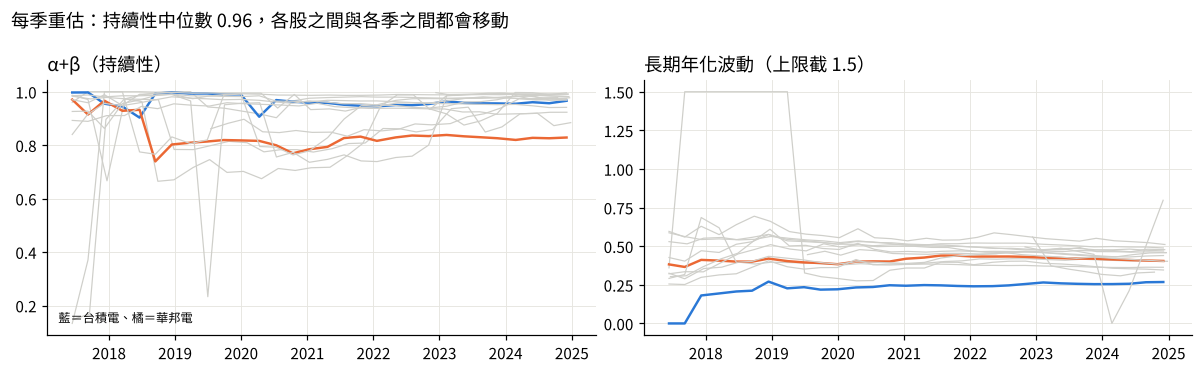

In [5]:
FITS["persistence"] = FITS.alpha + FITS.beta                 # 持續性
FITS["long_run_vol"] = np.sqrt(FITS.omega / (1 - FITS.persistence).clip(lower=1e-3) * 252) / 100  # 長期年化波動
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))             # 兩張
for sid, f in FITS.groupby("sid"):                           # 逐檔
    col = BLUE if sid == "2330" else (ORANGE if sid == "2344" else "#cfcfca")  # 兩檔標色，其餘灰
    axs[0].plot(pd.to_datetime(f.fit_end), f.persistence, color=col, lw=1.6 if col != "#cfcfca" else .8)  # 持續性
    axs[1].plot(pd.to_datetime(f.fit_end), f.long_run_vol.clip(upper=1.5), color=col, lw=1.6 if col != "#cfcfca" else .8)  # 長期波動
axs[0].set_title("α+β（持續性）"); axs[1].set_title("長期年化波動（上限截 1.5）")  # 標題
axs[0].text(.02, .05, "藍＝台積電、橘＝華邦電", transform=axs[0].transAxes, fontsize=8)  # 說明
fig.suptitle(f"每季重估：持續性中位數 {FITS.persistence.median():.2f}，各股之間與各季之間都會移動", x=.01, ha="left", fontsize=12)  # 總標題
save(fig, "04_garch_params.png")                             # 存圖

## E. 增量評估：只用驗證期（2022–2024）
依**標籤結束日**切：結束日在封存期之前的才算。三個問題：
1. GARCH 預測本身能不能排序（IC）？
2. 扣掉 HV20 已知的部分後，還剩多少（每日把 GARCH 排名對 HV20 排名做回歸，取殘差的 IC）？
3. 直接當預測用：MAE、QLIKE、以及「每日平均水準」跟實際的相關（整體配置看的就是這個）。

In [6]:
smp = pd.read_parquet(PROC / "samples.parquet")              # 標籤與特徵
smp = smp[smp.sid.isin(STK) & smp.eligible].merge(gf, on=["date", "sid"], how="left")  # 合併 GARCH 特徵
inval = np.zeros(len(smp), bool)                             # 是否在驗證窗內
for fd in FOLDS: inval |= ((smp.date >= fd["valid"][0]) & (smp.date <= fd["valid"][1])).values  # 三個驗證年度的聯集
va = smp[inval & smp.y.notna() & (smp.label_end < HOLDOUT_START)].copy()  # 依結束日封住封存期
print(f"驗證期樣本 {len(va):,} 筆，GARCH 覆蓋率 {va.garch_fc5.notna().mean():.1%}（5222、6770 上市後需 {BURN} 天暖身）")  # 印出
def resid_rank(t):                                           # 定義：每日把 GARCH 排名對 HV20 排名回歸，取殘差
    a, b = t.garch_fc5.rank(), t.hv20_L20.rank()             # 兩個排名
    beta = np.cov(a, b)[0, 1] / b.var(); return a - beta * b # 殘差＝HV20 解釋不到的部分
v2 = va.dropna(subset=["garch_fc5", "hv20_L20"]).copy()      # 兩者都有值
v2["garch_resid"] = v2.groupby("date", group_keys=False).apply(resid_rank, include_groups=False)  # 每日殘差
tab = pd.DataFrame({k: hac_stats(ic_by_date(v2, c), H) for k, c in
                    [("HV20", "hv20_L20"), ("GARCH 5 日預測", "garch_fc5"), ("GARCH 一步預測", "garch_vol1"),
                     ("ATR_14", "atr_p_L20"), ("GARCH 扣掉 HV20 後", "garch_resid")]}).T  # 各自的 IC 與 HAC
display(tab.round(4))                                        # 顯示
dec = v2[v2.is_decision]                                     # 決策日
oos = pd.read_parquet(PROC / "oos_validation.parquet")       # 05_validate 的樣本外預測
oos = oos[oos.model.isin(["ridge", "lgbm"]) & (oos.fold != "calib2021") & (oos.label_end < HOLDOUT_START)].pivot_table(index=["date", "sid"], columns="model", values="p").reset_index()  # Ridge、LightGBM 預測
dec = dec.merge(oos, on=["date", "sid"], how="left")         # 合併
def evalp(p):                                                # 定義：預測指標
    ok = dec[p].notna(); y, q = dec.y[ok], dec[p][ok]        # 有值的列
    lv = dec[ok].groupby("date")[[p, "y"]].mean()            # 每日平均水準
    return {"MAE": (q - y).abs().mean(), "QLIKE": (y**2 / q**2 - np.log(y**2 / q**2) - 1).mean(),
            "平均預測": q.mean(), "平均實際": y.mean(), "水準相關（每日平均）": lv.corr().iloc[0, 1], "n": int(ok.sum())}  # 回傳
cmpf = pd.DataFrame({k: evalp(c) for k, c in [("HV20", "hv20_L20"), ("GARCH 5 日預測", "garch_fc5"), ("Ridge", "ridge"), ("LightGBM", "lgbm")]}).T  # 比較
display(cmpf.round(4))                                       # 顯示
# 正式的 garch_features.parquet 由管線 src/03b_features_v2.py 產生；這裡只做檢查，不覆寫
FITS.to_csv(NB_OUT / "garch_fits.csv", index=False)          # 寫出每次估計的參數

驗證期樣本 10,371 筆，GARCH 覆蓋率 95.8%（5222、6770 上市後需 250 天暖身）


,ic_mean,ic_lo,ic_hi,hac_t,naive_t,hac_p,n_dates
HV20,0.4076,0.3685,0.4467,20.4349,40.2941,0.0,721.0
GARCH 5 日預測,0.3828,0.3438,0.4217,19.2566,37.3972,0.0,721.0
GARCH 一步預測,0.4069,0.3685,0.4452,20.8031,40.3503,0.0,721.0
ATR_14,0.4385,0.4026,0.4743,23.9528,46.7997,0.0,721.0
GARCH 扣掉 HV20 後,0.1479,0.1110,0.1848,7.8642,14.3730,0.0,721.0


,MAE,QLIKE,平均預測,平均實際,水準相關（每日平均）,n
HV20,0.1309,0.5953,0.3430,0.3317,0.4259,1983.0
GARCH 5 日預測,0.1408,0.4704,0.3879,0.3317,0.4567,1983.0
Ridge,0.1277,0.4443,0.3632,0.3317,0.4450,1983.0
LightGBM,0.1192,0.5019,0.3185,0.3317,0.4456,1983.0


**怎麼讀上面兩張表**：如果「GARCH 扣掉 HV20 後」的 IC 區間不含 0，代表 GARCH 帶來 HV20 沒有的排序資訊；
「水準相關」越高，代表整體風險高低判斷得越準——這是 70／50／30% 配置真正依賴的量。
結果與建議寫在 05 的結論與交付訊息中。